# 04 – Cylinder formula for the muon

## 1. Introduction

In the 0–20 GeV range the muon **does not start a cascade**: it passes straight through the detector and along its path deposits a nearly constant
amount of energy by ionisation (minimum ionising particle). It is like a **bullet drilling a straight
channel through wood**: the hole is equally thick all the way.

- **Depth, $L$:** a "plateau": fast rise at entry, nearly constant section, then a cut-off at the range $\ell$.
  $L \propto \sigma\!\left(\tfrac{z'-z_s}{w_1}\right)\sigma\!\left(\tfrac{\ell-z'}{w_2}\right)e^{\kappa z'/1000}$.
  At high momentum $\ell$ lies beyond the detector (the muon exits); at low momentum (below ~1 GeV) the muon stops in the detector.
- **Cross-section, $T$:** very narrow core (the track) and a weak tail (delta electrons, secondary particles).

**Coordinates (shower-local coordinates):** the same as in notebooks 01–03.
- $z'$ (`z_local`): depth along the direction of incidence, in mm (origin at the centroid of the first hit layer; for oblique incidence negative $z'$ also occurs).
- $r = \sqrt{x_{local}^2 + y_{local}^2}$: the hit's perpendicular distance from the track line, in mm; mirrored ($\pm r$) in 2D plots.
- The measured $r$ is that of the cell centre (~48 mm), so for the muon the narrow core width is constrained mainly by the detector convolution.

The shape is therefore a **cylinder** whose length is the range at low momentum and the detector depth at higher momentum.

Every parameter is a polynomial in $\ln p$; this formula is fitted **directly to the data** and is the physical reference (baseline) for the muon.

**Reference:**
- Particle Data Group, *Review of Particle Physics*, "Passage of particles through matter" chapter (Bethe formula, MIPs, CSDA range);
  [pdg.lbl.gov](https://pdg.lbl.gov).
- D. E. Groom, N. V. Mokhov, S. I. Striganov: *Muon stopping power and range tables 10 MeV–100 TeV*, At. Data Nucl. Data Tables 78 (2001) 183,
  [doi:10.1006/adnd.2001.0861](https://doi.org/10.1006/adnd.2001.0861).

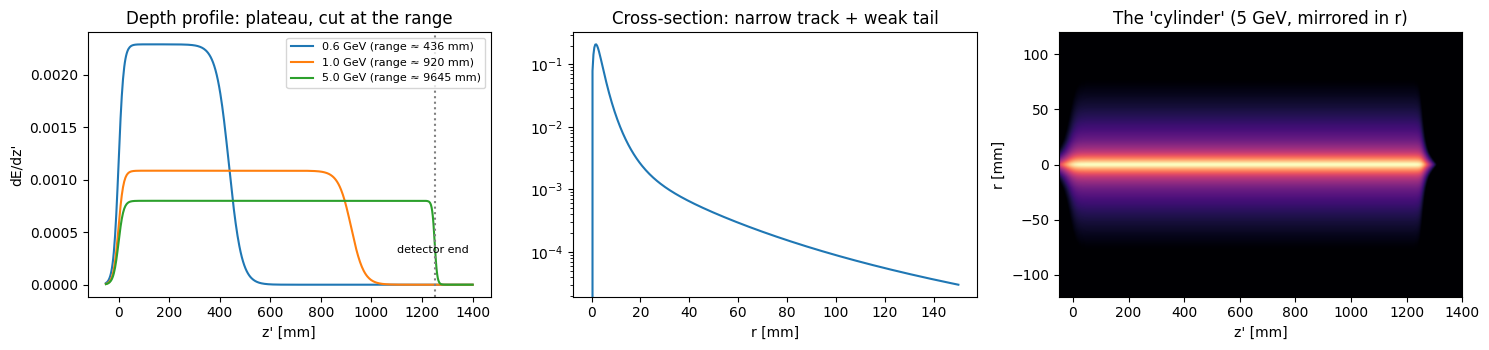

In [1]:
import numpy as np, matplotlib.pyplot as plt

z = np.linspace(-50, 1400, 600)
sig = lambda x: 1 / (1 + np.exp(-x))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for p in (0.6, 1.0, 5.0):
    ell = 920 * p ** 1.46                   # illustrative range-momentum relation [mm]
    L = sig(z / 10) * sig((ell - z) / 25) * sig((1250 - z) / 5)
    ax[0].plot(z, L / np.trapezoid(L, z), label=f"{p} GeV (range ≈ {min(ell, 9999):.0f} mm)")
ax[0].axvline(1250, c="grey", ls=":"); ax[0].text(1100, 0.0003, "detector end", fontsize=8)
ax[0].set(title="Depth profile: plateau, cut at the range", xlabel="z' [mm]", ylabel="dE/dz'"); ax[0].legend(fontsize=8)
r = np.linspace(0, 150, 400); Rc, Rt, pc = 3.0, 40.0, 0.97
T = (pc * Rc**2 / (r**2 + Rc**2)**2 + (1 - pc) * Rt**2 / (r**2 + Rt**2)**2) / np.pi
ax[1].semilogy(r, 2 * np.pi * r * T); ax[1].set(title="Cross-section: narrow track + weak tail", xlabel="r [mm]")
Z, R = np.meshgrid(z, np.linspace(-120, 120, 241))
rho = sig(Z / 10) * sig((1250 - Z) / 5) * (Rc**2 / (R**2 + Rc**2)**2 * pc + (1 - pc) * Rt**2 / (R**2 + Rt**2)**2)
ax[2].imshow(np.log10(rho + 1e-30), extent=[z[0], z[-1], -120, 120], aspect="auto", origin="lower", cmap="magma",
             vmin=np.log10(rho.max()) - 5)
ax[2].set(title="The 'cylinder' (5 GeV, mirrored in r)", xlabel="z' [mm]", ylabel="r [mm]")
plt.tight_layout(); plt.show()

## 2. Loading data

In [2]:
PARTICLES = ['muon']
DATA_DIR = "../../data/simulations/regression-muon/"          # location of the CSVs
OUT_DIR = "results"        # models and exports go here
%run -i ./00_common.ipynb

/home/user/.venv/lib/python3.10/site-packages/nbformat/__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


device: cuda | data: ../../data/simulations/regression-muon/ | output: results


In [3]:
DATA = {}
for particle in PARTICLES:
    df, geo, DATA[particle] = load_data(particle)
    print(f"\n===== {particle} =====")
    df.info()
    display(df.describe().T)
    display(df.head())

muon: 99797 events, geometry {'layer': 20.5, 'cell': 48.59999999999991, 'z_back': 4882.15}, split train 69858, val 14969, test 14970

===== muon =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5067631 entries, 0 to 5067630
Data columns (total 21 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   event_number                int64  
 1   cellID                      int64  
 2   x                           float64
 3   y                           float64
 4   z                           float64
 5   x_local                     float64
 6   y_local                     float64
 7   z_local                     float64
 8   x_trans                     float64
 9   y_trans                     float64
 10  z_trans                     float64
 11  energy                      float64
 12  earliest_contribution_time  float64
 13  incoming_momentum           float64
 14  incoming_theta              float64
 15  incoming_phi                float6

,count,mean,std,min,25%,50%,75%,max
event_number,5067631.0,1.050881e+05,6.059986e+04,0.000000e+00,5.251400e+04,1.051720e+05,1.577220e+05,2.099970e+05
cellID,5067631.0,2.235442e+09,1.528754e+09,4.724000e+03,1.078464e+09,2.164590e+09,3.410281e+09,5.063386e+09
x,5067631.0,4.563739e+00,1.303354e+03,-2.596035e+03,-1.036428e+03,3.040900e+01,1.041428e+03,2.601035e+03
y,5067631.0,7.028338e+00,1.307724e+03,-2.599800e+03,-1.036200e+03,2.620000e+01,1.036200e+03,2.599800e+03
z,5067631.0,4.215911e+03,3.512256e+02,3.662400e+03,3.908400e+03,4.195400e+03,4.502900e+03,4.871900e+03
x_local,5067631.0,-1.138769e+00,3.522868e+01,-2.312273e+03,-1.600449e+01,-1.002594e+00,1.390341e+01,1.703387e+03
y_local,5067631.0,-8.514499e-02,3.379383e+01,-1.721513e+03,-1.533235e+01,0.000000e+00,1.517229e+01,2.063125e+03
z_local,5067631.0,5.947941e+02,3.769971e+02,-1.132517e+03,2.676178e+02,5.697328e+02,9.091533e+02,1.623868e+03
x_trans,5067631.0,4.181690e-01,1.917018e+02,-2.706329e+03,-1.009449e+02,0.000000e+00,1.009449e+02,1.663381e+03
y_trans,5067631.0,8.447938e-01,1.920975e+02,-1.668400e+03,-1.010000e+02,0.000000e+00,1.010000e+02,2.186630e+03


,event_number,cellID,x,y,z,x_local,y_local,z_local,x_trans,y_trans,...,energy,earliest_contribution_time,incoming_momentum,incoming_theta,incoming_phi,incoming_momentum_bin,particle_type,is_secondary,parent_type,daughter_type
0,176421,5058537844,-1435.802002,1339.199951,4871.899902,9.502957,-23.063114,1309.566015,-355.508057,355.399963,...,0.000630,17.535614,3.817813,0.386266,2.402242,3,mu-,0,NaN,e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e...
1,143783,1657341556,1949.927979,-935.200012,3826.399902,18.133007,-3.520068,198.721541,100.943970,-52.400024,...,0.000787,14.673748,13.625557,0.515130,-0.447856,13,mu-,0,NaN,e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e...
2,143288,3326742132,1238.912964,-1339.199951,4195.399902,-0.587278,-0.951270,579.926957,153.619019,-169.200244,...,0.000567,15.240423,7.420113,0.406068,-0.829464,7,mu-,0,NaN,e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e...
3,46874,2886257012,1791.905029,-834.200012,4789.899902,-11.030487,-16.424030,1214.374557,403.778076,-202.000000,...,0.000660,17.279598,17.166748,0.389733,-0.427482,17,mu-,0,NaN,e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e...
4,165339,30024564,-878.405029,-1387.800049,3662.399902,-0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000640,13.388048,4.648698,0.419454,-2.145584,4,mu-,0,NaN,e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e...


## 3. The model

`Formula("plateau", "core_tail")`, with first-degree $\ln p$ dependence. The range parameter is `log_ell`, i.e. $\ell = e^{c_0 + c_1 \ln p} = e^{c_0} p^{c_1}$,
which is exactly the power-law form of the range–momentum relation.

### What is fitted, and what affects the fit?

**Fitted features (in the likelihood):**
- **Position:** `x_local, y_local, z_local` → $z' =$ `z_local`, $r = \sqrt{x_{local}^2 + y_{local}^2}$. The formula sees only these two coordinates.
- **Weight:** `energy`, normalised to 1 per event ($w_i$). The fit seeks the energy-weighted **mean shape**; every event counts equally.
- **Condition:** `incoming_momentum` → $\ln p$. Every formula parameter is a polynomial in $\ln p$, so a single fit gives the shape for all momenta.
- **Grouping:** `event_number`: normalisation and NLL are computed per event.

**What affects the fit but is not a fitted target:**
- `incoming_theta`, `incoming_phi` → rotation: used to rotate the detector cell into the shower frame for the convolution.
- `z`, `z_trans` (+ `incoming_theta`) → the detector back face along the axis ($z_b$). The likelihood normalisation only considers the part in front of the back face; the shape beyond it is not constrained by data.
- `x`, `y`, `z` → geometry: cell size (~48 mm) and layer spacing (~20.5 mm). This is how much the formula is "smeared" before comparison with the data.
- **Cuts:** `earliest_contribution_time` < 100 ns, $Z_{MIN} \le z' \le Z_{MAX}$, $r < R_{MAX}$.
- `incoming_momentum_bin` → only needed for stratifying the train/val/test split.
- **Initial values** (`init_from`): from the training hits' $z'$, $r$, $w$ (weighted mean depth, depth spread, median radius; the initial range $\ell$ is the 97% quantile of the weighted $z'$).
- **Training:** Adam optimiser (`lr`), early stopping on the validation NLL (`patience=15`). No smoothness penalty, since the formula is smooth by construction.

In [4]:
data = DATA["muon"]
h = data["train"].hits()
model = Formula("plateau", "core_tail", degree=1).init_from(h.z.values, h.r.values, h.w.values).to(DEVICE)
print("parameters:", model.n_params())
display(Markdown(model.describe("Initial values")))

parameters: 19


/tmp/ipykernel_322053/1674953462.py:114: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  terms = " ".join(f"{float(v):+.4g}" + ("" if k == 0 else rf"\,{L}" if k == 1 else rf"\,{L}^{k}")


### Initial values

$$L \propto \sigma\!\left(\frac{z'-z_s}{w_1}\right)\sigma\!\left(\frac{\ell-z'}{w_2}\right)e^{\kappa z'/1000}$$

$$T = \frac{p_c}{\pi}\frac{R_C^2}{(r^2+R_C^2)^2}+\frac{1-p_c}{\pi}\frac{R_T^2}{(r^2+R_T^2)^2}$$

| parameter | value, $L=\ln(p/\mathrm{GeV})$ | depth slope (× z'/1000) |
|---|---|---|
| `zs` | $-10 +0\,L$ | – |
| `log_w1` | $+2.708 +0\,L$ | – |
| `log_ell` | $+7.125 +0\,L$ | – |
| `log_w2` | $+3.401 +0\,L$ | – |
| `kappa` | $+0 +0\,L$ | – |
| `log_rc` | $+2.494 +0\,L$ | +0 |
| `log_ratio` | $+1.099 +0\,L$ | +0 |
| `logit_pc` | $+0.85 +0\,L$ | +0 |

Number of parameters: **19**

## 4. Training

The model is saved to `results/muon/cylinder.pt`; if training has already run, it is just loaded.

Settings: `epochs=150`, `lr=0.03`, muon data only. The range $\ell$ is constrained **only** by data in front of the back face: if the muon exits the detector ($\ell > z_b$), the fit sees only a lower bound on it. Its $\ln p$ dependence is then determined by the low-momentum, stopping muons.

loaded finished model from results/muon/cylinder.pt


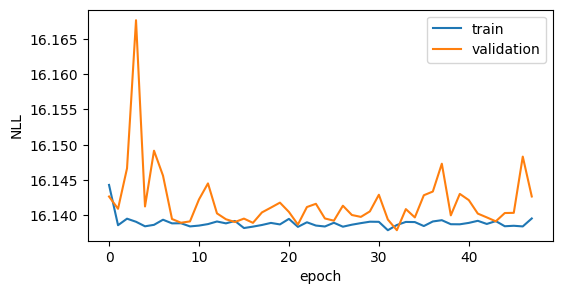

In [5]:
hist = fit(model, data, f"{OUT_DIR}/muon/cylinder.pt", epochs=150, lr=0.03)
plt.figure(figsize=(6, 3)); plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="validation")
plt.xlabel("epoch"); plt.ylabel("NLL"); plt.legend(); plt.show()

## 4b. Selecting the degree of the $\ln p$ polynomial

Besides the $n=1$ model above, we also fit degrees $n = 1 \dots 6$ (`select_degree`; protocol in section 7 of the common notebook).
The degree is chosen on the **validation** set; the **test** set only measures the final model. Models are saved to `results/muon/cylinder_n<n>.pt`;
a completed training is just loaded.

**What to look for:** the train curve always decreases with $n$. If the validation curve flattens or turns back, further
degrees only fit noise.

--- degree 1 ---
loaded finished model from results/muon/cylinder_n1.pt


--- degree 2 ---
loaded finished model from results/muon/cylinder_n2.pt


--- degree 3 ---
loaded finished model from results/muon/cylinder_n3.pt


--- degree 4 ---
loaded finished model from results/muon/cylinder_n4.pt


--- degree 5 ---
loaded finished model from results/muon/cylinder_n5.pt


--- degree 6 ---
loaded finished model from results/muon/cylinder_n6.pt


lowest validation NLL: n* = 6;  chosen by the 1-SE rule: n = 6


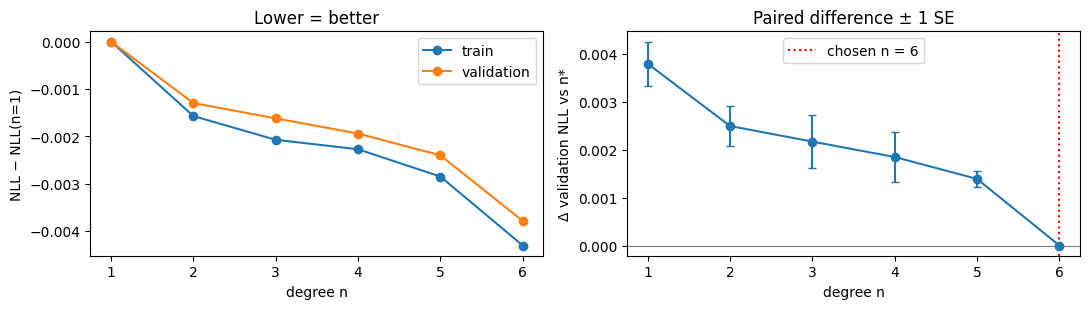

,params,train NLL,val NLL,epochs,Δval vs n*,SE,chosen
n,,,,,,,
1,19,16.0892,16.0908,20,0.0038,0.0005,
2,27,16.0876,16.0895,25,0.0025,0.0004,
3,35,16.0871,16.0892,32,0.0022,0.0005,
4,43,16.0869,16.0889,47,0.0018,0.0005,
5,51,16.0864,16.0884,24,0.0014,0.0002,
6,59,16.0849,16.0870,24,0.0000,0.0000,◀


chosen degree: 6 | test NLL n=1: 16.0956 | chosen: 16.0899


In [6]:
model_n1 = model
model, DEGREE_TABLE, DEGREE_MODELS = select_degree("plateau", "core_tail", data, "muon", "cylinder", degrees=range(1, 7),
                                                   epochs=150, lr=0.03)
display(DEGREE_TABLE.round(4))
print("chosen degree:", model.degree, "| test NLL n=1:", round(float(test_nll(model_n1, data["test"]).mean()), 4),
      "| chosen:", round(float(test_nll(model, data["test"]).mean()), 4))

## 6. Results

**What to look for:**
- **`ell`:** the range should be of order 1 m around 1 GeV, and above that grow beyond the detector depth.
- **`kappa`:** a negative value indicates that the measured profile decreases with depth. For a MIP this is not a physical effect; it is probably caused by oblique tracks
  exiting through the side (see the discussion).
- **Profile:** the data show a sharp peak in the first layer that the formula does not reproduce. This is an open question related to the definition of the origin or to material
  in front of the detector.

### The fitted cylinder formula

$$L \propto \sigma\!\left(\frac{z'-z_s}{w_1}\right)\sigma\!\left(\frac{\ell-z'}{w_2}\right)e^{\kappa z'/1000}$$

$$T = \frac{p_c}{\pi}\frac{R_C^2}{(r^2+R_C^2)^2}+\frac{1-p_c}{\pi}\frac{R_T^2}{(r^2+R_T^2)^2}$$

| parameter | value, $L=(\ln(p/\mathrm{GeV}) -0.04485)/2.951$ | depth slope (× z'/1000) |
|---|---|---|
| `zs` | $-8.098 -1.465\,L -0.3256\,L^2 +2.618\,L^3 -1.679\,L^4 +0.3169\,L^5 -0.4709\,L^6$ | – |
| `log_w1` | $+0.6189 -0.6606\,L +1.442\,L^2 +0.4047\,L^3 -1.489\,L^4 -0.2043\,L^5 -0.1322\,L^6$ | – |
| `log_ell` | $+6.876 +3.499\,L -0.7892\,L^2 +0.09207\,L^3 -5.981\,L^4 +10.31\,L^5 -5.203\,L^6$ | – |
| `log_w2` | $+3.148 +2.921\,L +1.645\,L^2 -2.293\,L^3 +0.04441\,L^4 -0.1571\,L^5 +0.3984\,L^6$ | – |
| `kappa` | $-0.9399 -0.6789\,L +1.95\,L^2 -1.061\,L^3 -0.5191\,L^4 +0.2432\,L^5 +0.1223\,L^6$ | – |
| `log_rc` | $+2.255 +0.7257\,L +0.4558\,L^2 -1.522\,L^3 +0.1157\,L^4 +0.6556\,L^5 -0.1115\,L^6$ | +0.2207 |
| `log_ratio` | $-0.807 -4.92\,L -6.641\,L^2 +8.222\,L^3 +6.771\,L^4 -16.38\,L^5 -1.811\,L^6$ | +2.767 |
| `logit_pc` | $+6.248 -0.6351\,L -0.4952\,L^2 +6.143\,L^3 +3.516\,L^4 -3.727\,L^5 -0.244\,L^6$ | -182.6 |

Number of parameters: **59**

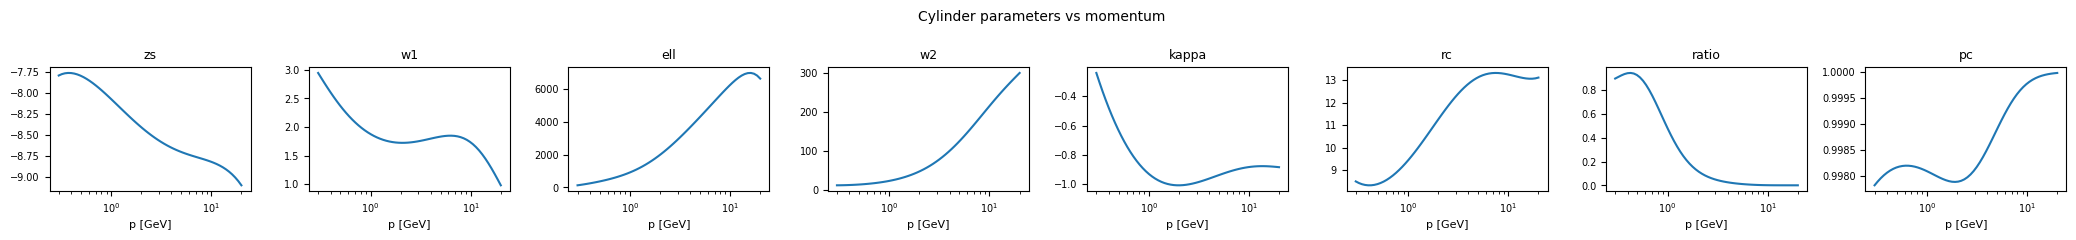

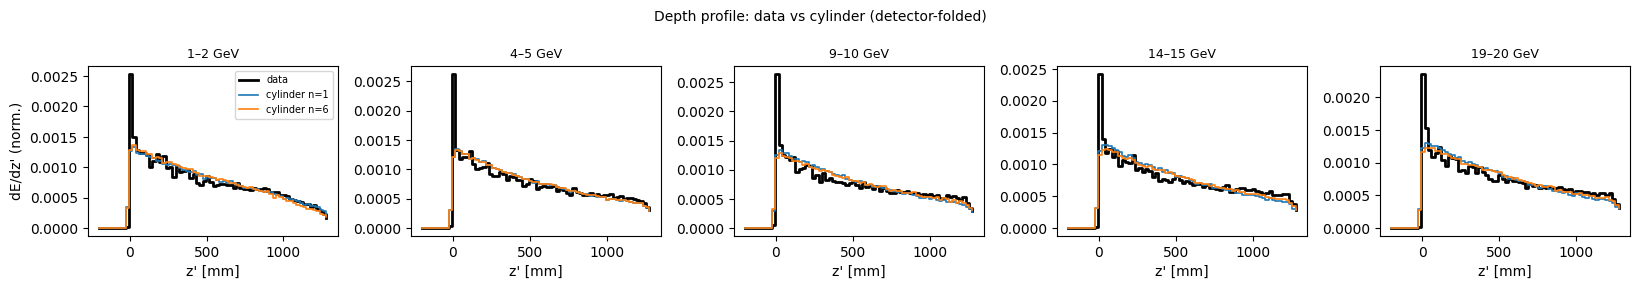

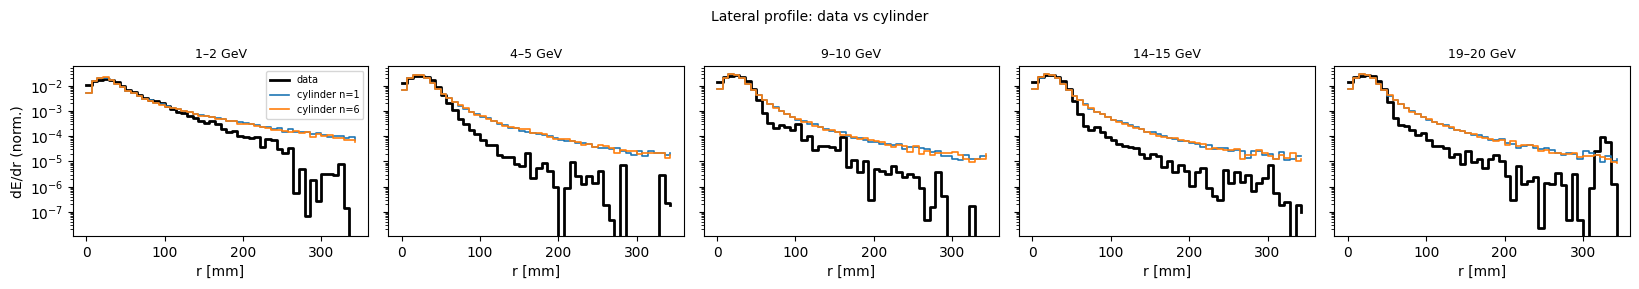

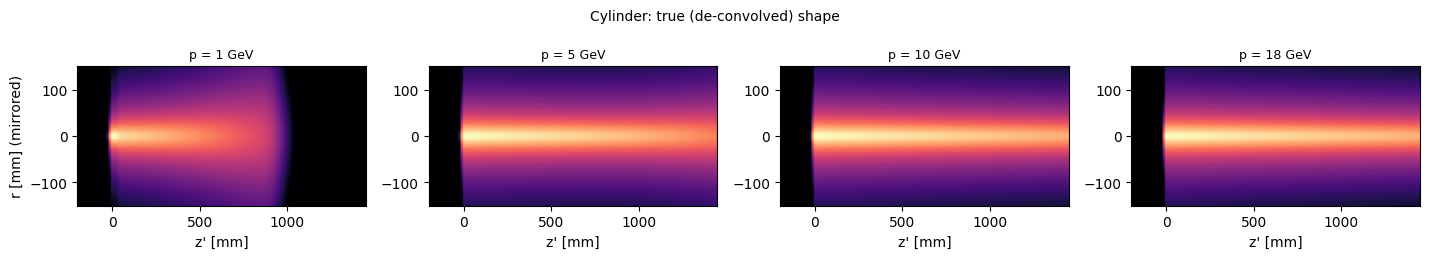

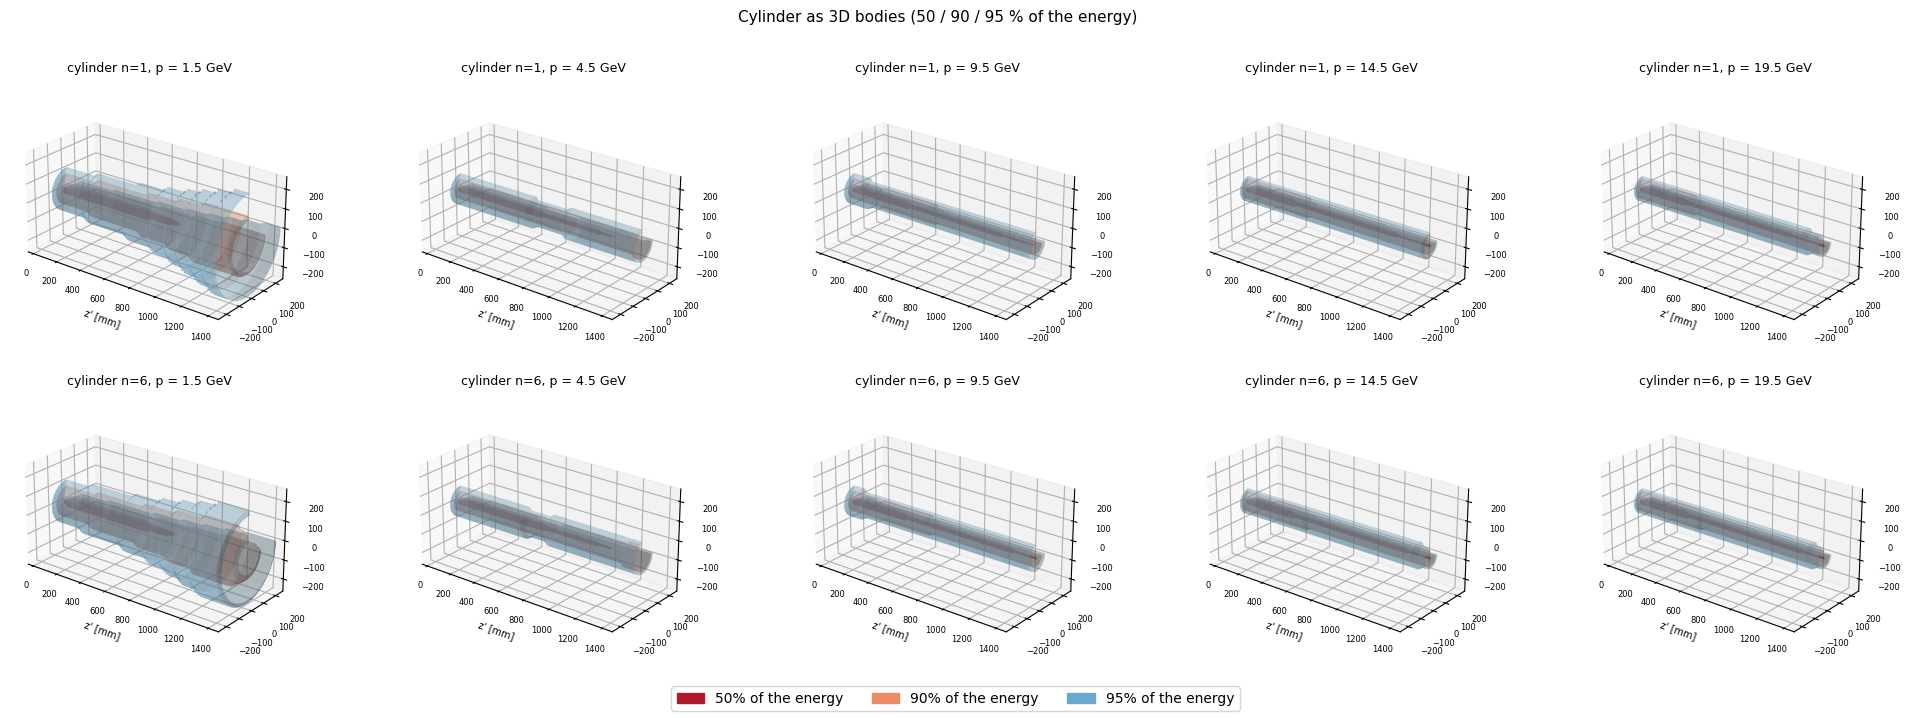

exported muon/cylinder: test NLL = 16.0899


In [7]:
display(Markdown(model.describe("The fitted cylinder formula")))
formula_curves(model, "Cylinder parameters vs momentum")
samples = {"cylinder n=1": sample_folded(model_n1, data["test"]), f"cylinder n={model.degree}": sample_folded(model, data["test"])}
hits = data["test"].hits()
profile_plot(hits, samples, "z", "Depth profile: data vs cylinder (detector-folded)")
profile_plot(hits, samples, "r", "Lateral profile: data vs cylinder")
shape_map(model, title="Cylinder: true (de-convolved) shape")
bodies_3d({"cylinder n=1": model_n1, f"cylinder n={model.degree}": model}, title="Cylinder as 3D bodies (50 / 90 / 95 % of the energy)")
export("muon", "cylinder", model, data, model.describe("Cylinder (muon baseline)"))